# 04 - Exploratory Data Analysis (EDA)

**Sections:** 1) Setup  2) Prepare the data  3) Salary and outliers  4) Attrition by job role  5) Overtime  6) Age and years at company  7) Promotion  8) Self rating vs manager rating  9) Satisfaction  10) More factors  11) Sales Representative deep dive  12) High-risk segment and KPIs

## 1. Setup and chart style
**Chart rules used in this notebook** (to keep the charts easy to read):
1. **Colors have one meaning.** Blue = employees who stayed, red = employees who left or a rate above the company rate, grey = reference or below the company rate, orange = overtime.

In [28]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

# ---- Colors (colour-blind friendly) ----
COLORS = {
    "stayed": "#4C78A8",   # blue
    "left": "#E45756",     # red
    "neutral": "#A0AEC0",  # grey
    "accent": "#F28E2B",   # orange (overtime)
    "primary": "#5B7DB1",  # single-series bars
    "text": "#2D3748",
    "grid": "#E2E8F0",
}

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.edgecolor": COLORS["grid"],
    "grid.color": COLORS["grid"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["text"],
    "xtick.color": COLORS["text"],
    "ytick.color": COLORS["text"],
    "axes.grid.axis": "y",      # horizontal grid lines only (cleaner for vertical bars)
})

os.makedirs("../images", exist_ok=True)

def save_chart(name):
    plt.tight_layout()
    plt.savefig(f"../images/{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

def add_labels(ax, fmt="%.1f%%", fontsize=9, padding=3):
    """Write the value on each bar, on a white background so lines never cross the text."""
    for container in ax.containers:
        texts = ax.bar_label(container, fmt=fmt, padding=padding, fontsize=fontsize)
        for t in texts:
            t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))

def label_bars(ax, bars, labels, padding=3, fontsize=9):
    """Same as add_labels, but with custom label text (for example rate + group size)."""
    texts = ax.bar_label(bars, labels=labels, padding=padding, fontsize=fontsize)
    for t in texts:
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))

def add_headroom(ax, axis="y", extra=0.15):
    """Leave empty space after the longest bar so labels never touch the frame."""
    if axis == "y":
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi * (1 + extra))
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi * (1 + extra))

def percent_axis(ax, axis="y"):
    fmt = mtick.PercentFormatter(xmax=100, decimals=0)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def k_axis(ax, axis="x"):
    fmt = mtick.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

print("Ready")

Ready


## 2. Prepare the data
We read the **clean** files from notebook 01.

- `Status` is the same information as text (Left / Stayed), used to color the charts.

In [29]:
employee = pd.read_csv("../data/clean/employee_clean.csv", parse_dates=["HireDate"])
performance = pd.read_csv("../data/clean/performance_clean.csv", parse_dates=["ReviewDate"])

employee = employee.rename(columns={"DistanceFromHome (KM)": "DistanceFromHome_KM"})
employee["Left"] = (employee["Attrition"] == "Yes").astype(int)
employee["Status"] = employee["Attrition"].map({"Yes": "Left", "No": "Stayed"})
employee["AgeGroup"] = pd.cut(employee["Age"], bins=[17, 25, 35, 45, 55],
                              labels=["18-25", "26-35", "36-45", "46-55"])

company_rate = employee["Left"].mean() * 100
print(f"Company attrition rate: {company_rate:.1f}%")
print("Employees:", len(employee), "| Reviews:", len(performance))

Company attrition rate: 16.1%
Employees: 1470 | Reviews: 6709


## 3. Salary distribution and outliers
An **outlier** is a value far away from the others. Before trusting averages, we check the salary distribution.

- **Histogram** (left): how many employees are in each salary range.
- **Box plot** (right): one pair of boxes per job role. Blue = employees who stayed, red = employees who left. The box holds the middle 50% of the values, the line inside is the **median**, and the dots are possible outliers.

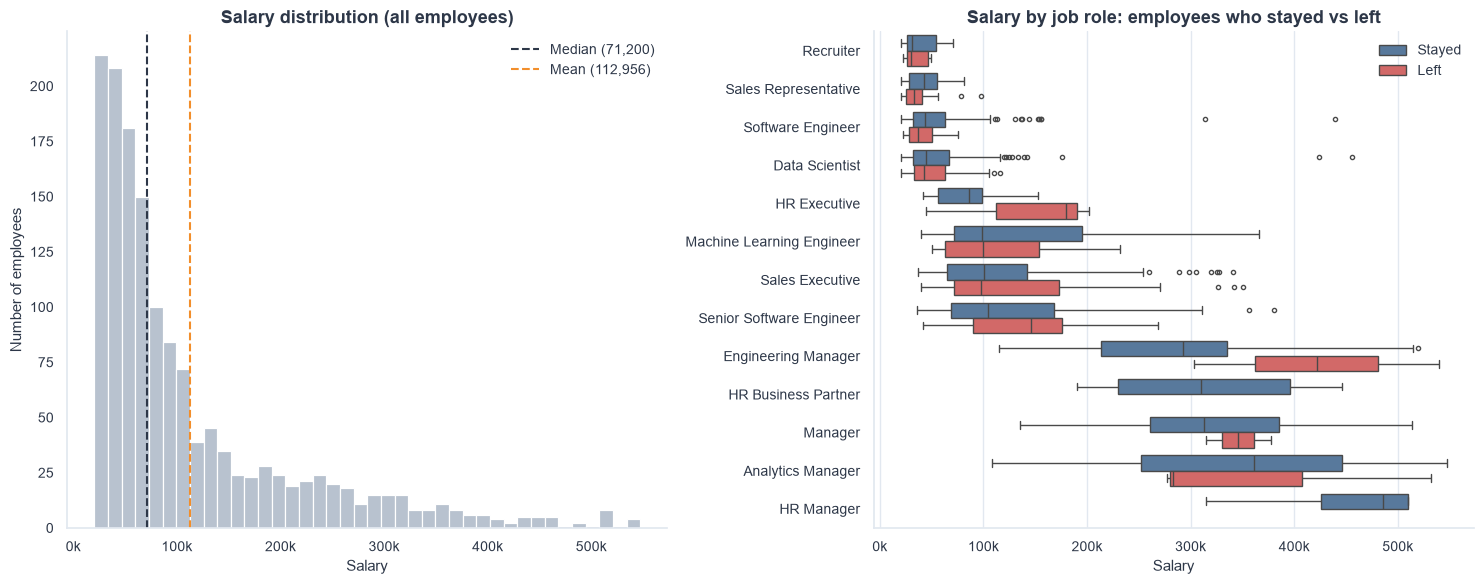

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

median_salary = employee["Salary"].median()
mean_salary = employee["Salary"].mean()

sns.histplot(employee["Salary"], bins=40, color=COLORS["neutral"], edgecolor="white", ax=axes[0])
axes[0].axvline(median_salary, color=COLORS["text"], linestyle="--", linewidth=1.5, label=f"Median ({median_salary:,.0f})")
axes[0].axvline(mean_salary, color=COLORS["accent"], linestyle="--", linewidth=1.5, label=f"Mean ({mean_salary:,.0f})")
axes[0].set_title("Salary distribution (all employees)")
axes[0].set_xlabel("Salary")
axes[0].set_ylabel("Number of employees")
k_axis(axes[0], "x")
axes[0].grid(axis="y")
axes[0].legend(frameon=False, loc="upper right")

order = employee.groupby("JobRole")["Salary"].median().sort_values().index
sns.boxplot(data=employee, y="JobRole", x="Salary", hue="Status", hue_order=["Stayed", "Left"],
            palette={"Stayed": COLORS["stayed"], "Left": COLORS["left"]}, order=order,
            linewidth=1, fliersize=3, ax=axes[1])
axes[1].set_title("Salary by job role: employees who stayed vs left")
axes[1].set_xlabel("Salary")
axes[1].set_ylabel("")
k_axis(axes[1], "x")
axes[1].grid(axis="x")
axes[1].grid(axis="y", visible=False)
axes[1].legend(title="", frameon=False, loc="upper right")

save_chart("01_salary_distribution")

Mean and median are different when the data is skewed. Compare them for each job role:

In [31]:
employee.groupby("JobRole")["Salary"].agg(employees="count", min="min", median="median", mean="mean", max="max").round(0).sort_values("median")

,employees,min,median,mean,max
JobRole,,,,,
Recruiter,24,20583,30854.0,37648.0,70703
Sales Representative,83,20650,36101.0,40656.0,97794
Software Engineer,294,20418,42704.0,51967.0,439641
Data Scientist,261,20387,44057.0,56079.0,455643
HR Executive,28,41745,89376.0,94362.0,201564
Machine Learning Engineer,146,39456,98598.0,130165.0,366078
Sales Executive,327,37035,100314.0,117196.0,350525
Senior Software Engineer,132,36012,106898.0,126161.0,380248
Engineering Manager,75,115110,292500.0,286259.0,539998


### Outlier check: overall vs inside each job role
The **IQR rule** marks a value as an outlier if it is more than 1.5 x IQR above Q3 or below Q1. (Q1 = 25% point, Q3 = 75% point, IQR = Q3 - Q1.)

Salaries are very different between roles, so we run the rule **twice**: on all employees, and inside each job role.

In [32]:
def iqr_outlier_mask(df, value_col, group_col=None):
    if group_col is None:
        q1, q3 = df[value_col].quantile([0.25, 0.75])
        iqr = q3 - q1
        return (df[value_col] < q1 - 1.5 * iqr) | (df[value_col] > q3 + 1.5 * iqr)
    g = df.groupby(group_col)[value_col]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return (df[value_col] < q1 - 1.5 * iqr) | (df[value_col] > q3 + 1.5 * iqr)

overall_mask = iqr_outlier_mask(employee, "Salary")
role_mask = iqr_outlier_mask(employee, "Salary", "JobRole")

print("Outliers when comparing with ALL employees:", overall_mask.sum())
print("Outliers when comparing inside each job role:", role_mask.sum())

print()
print("Overall outliers by job role (these are mostly high-paying management roles):")
print(employee[overall_mask]["JobRole"].value_counts())

Outliers when comparing with ALL employees: 124
Outliers when comparing inside each job role: 41

Overall outliers by job role (these are mostly high-paying management roles):
JobRole
Engineering Manager          39
Analytics Manager            32
Manager                      24
Sales Executive               9
Senior Software Engineer      5
HR Business Partner           4
HR Manager                    4
Machine Learning Engineer     3
Software Engineer             2
Data Scientist                2
Name: count, dtype: int64


In [33]:
print("Outliers inside their own job role (top 10 by salary):")
employee.loc[role_mask, ["EmployeeID", "JobRole", "Department", "Salary", "Attrition"]].sort_values("Salary", ascending=False).head(10)

Outliers inside their own job role (top 10 by salary):


,EmployeeID,JobRole,Department,Salary,Attrition
1167,1A7C-19DB,Engineering Manager,Technology,539998,Yes
961,8892-77D8,Engineering Manager,Technology,519361,No
1425,372C-E204,Data Scientist,Technology,455643,No
1194,801E-9D0E,Software Engineer,Technology,439641,No
1226,AFC3-E23F,Data Scientist,Technology,423941,No
1238,1A82-AF2C,Senior Software Engineer,Technology,380248,No
823,1424-0B0C,Senior Software Engineer,Technology,356378,No
147,DFE3-6FA7,Sales Executive,Sales,350525,Yes
1138,06DE-E772,Sales Executive,Sales,341971,Yes
302,CD59-7F94,Sales Executive,Sales,341039,No


## 4. Attrition by job role
Only roles with at least 30 employees. The dashed line is the company rate.

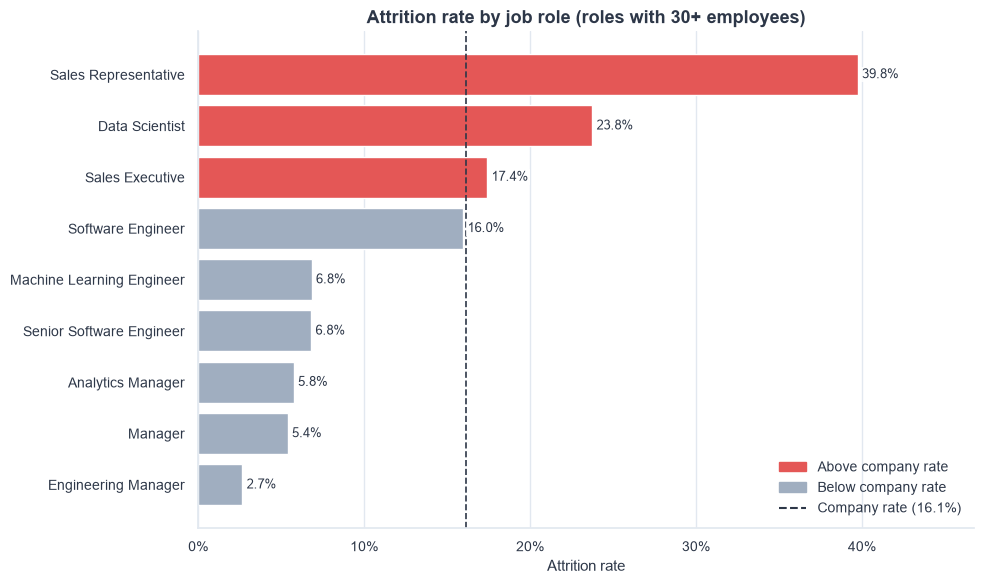

In [34]:
roles = employee.groupby("JobRole").filter(lambda g: len(g) >= 30)
role_rates = roles.groupby("JobRole")["Left"].mean().mul(100).sort_values()
bar_colors = [COLORS["left"] if v > company_rate else COLORS["neutral"] for v in role_rates.values]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(role_rates.index, role_rates.values, color=bar_colors)
ax.axvline(company_rate, color=COLORS["text"], linestyle="--", linewidth=1.2)
add_labels(ax)
add_headroom(ax, "x", 0.12)
percent_axis(ax, "x")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Attrition rate by job role (roles with 30+ employees)")
ax.set_xlabel("Attrition rate")
ax.set_ylabel("")
ax.legend(handles=[
    Patch(color=COLORS["left"], label="Above company rate"),
    Patch(color=COLORS["neutral"], label="Below company rate"),
    Line2D([0], [0], color=COLORS["text"], linestyle="--", label=f"Company rate ({company_rate:.1f}%)"),
], frameon=False, loc="lower right")
save_chart("02_attrition_by_job_role")

## 5. Overtime
First the overall difference, then the same comparison **inside each job role**. If the overtime gap stays inside most roles, it is not only caused by different job mixes.

          employees  attrition_rate_pct
OverTime                               
No             1054                10.4
Yes             416                30.5


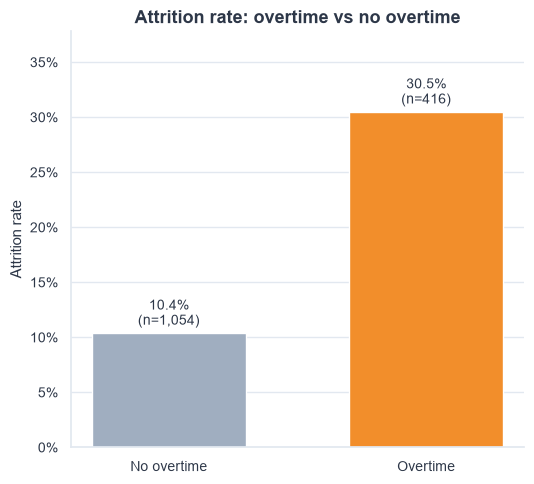

In [35]:
ot = employee.groupby("OverTime")["Left"].agg(employees="count", attrition_rate_pct=lambda s: s.mean() * 100).round(1)
print(ot)

fig, ax = plt.subplots(figsize=(5.5, 5))
bars = ax.bar(["No overtime", "Overtime"], ot["attrition_rate_pct"],
              color=[COLORS["neutral"], COLORS["accent"]], width=0.6)
label_bars(ax, bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in zip(ot["attrition_rate_pct"], ot["employees"])],
             padding=3, fontsize=10)
add_headroom(ax, "y", 0.18)
percent_axis(ax, "y")
ax.set_title("Attrition rate: overtime vs no overtime")
ax.set_ylabel("Attrition rate")
save_chart("03_attrition_by_overtime")

OverTime                     No   Yes
JobRole                              
Engineering Manager         1.9   4.8
Senior Software Engineer    7.4   5.4
Manager                     3.7  10.0
Machine Learning Engineer   5.6  10.3
Analytics Manager           0.0  25.0
Sales Executive            11.2  32.6
Software Engineer           7.1  33.7
Data Scientist             15.7  49.2
Sales Representative       28.8  66.7


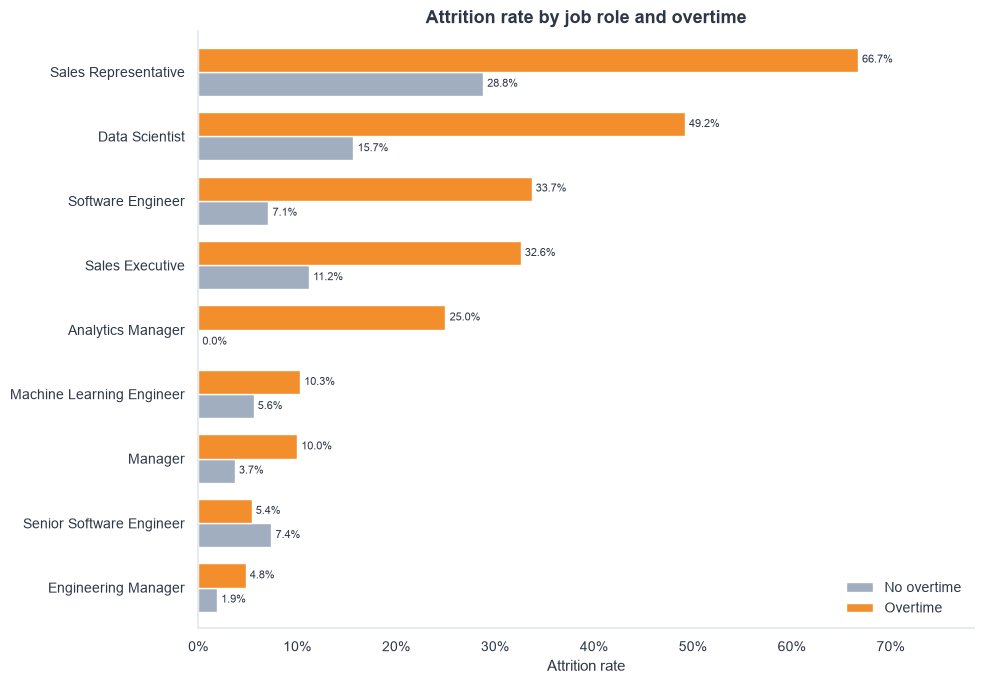

In [36]:
by_role_ot = (roles.pivot_table(index="JobRole", columns="OverTime", values="Left", aggfunc="mean") * 100).round(1)
by_role_ot = by_role_ot.sort_values("Yes")
print(by_role_ot)

plot_df = by_role_ot.rename(columns={"No": "No overtime", "Yes": "Overtime"})
ax = plot_df.plot(kind="barh", figsize=(10, 7), color=[COLORS["neutral"], COLORS["accent"]], width=0.75)
add_labels(ax, fontsize=8)
add_headroom(ax, "x", 0.12)
percent_axis(ax, "x")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Attrition rate by job role and overtime")
ax.set_xlabel("Attrition rate")
ax.set_ylabel("")
ax.legend(title="", frameon=False, loc="lower right")
save_chart("04_overtime_inside_job_roles")

## 6. Age and years at company
Two charts side by side.

          employees  rate
AgeGroup                 
18-25           650  18.0
26-35           497  19.5
36-45           252   7.5
46-55            71   5.6

                employees  rate
YearsAtCompany                 
0                     190  31.6
1                     177  34.5
2                     124  20.2
3                     148  16.2
4                     129  11.6
5                     115  17.4
6                     101  10.9
7                     121   7.4
8                     119   5.0
9                     118   4.2
10                    128   0.8


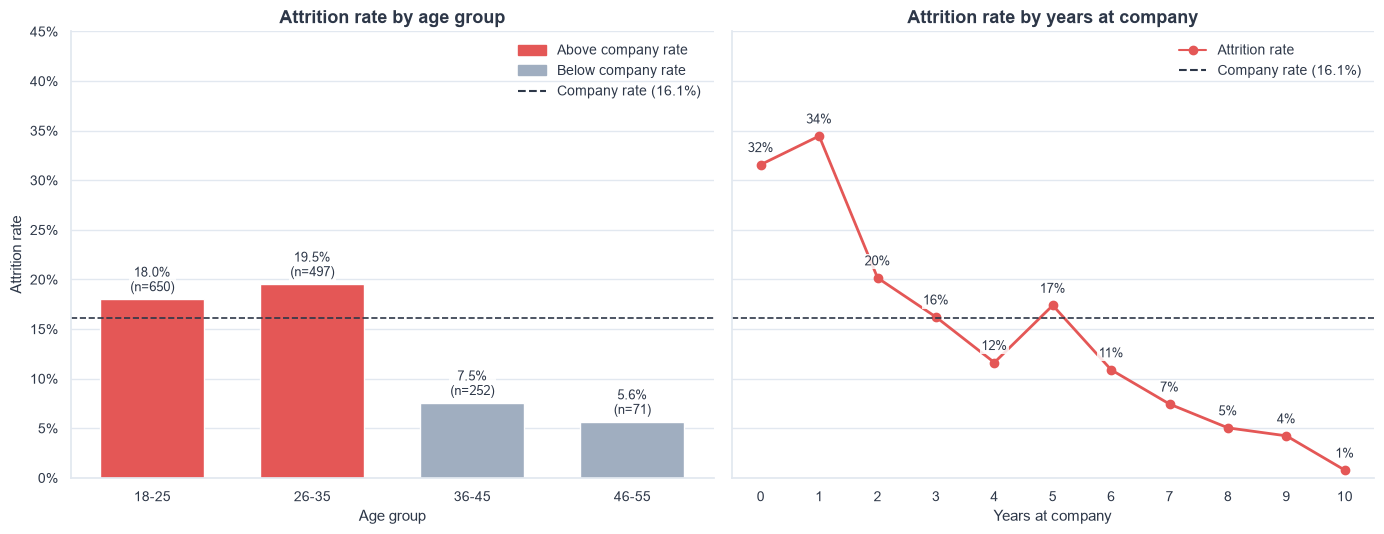

In [37]:
age_rates = employee.groupby("AgeGroup", observed=True)["Left"].agg(employees="count", rate=lambda s: s.mean() * 100)
tenure_rates = employee.groupby("YearsAtCompany")["Left"].agg(employees="count", rate=lambda s: s.mean() * 100)
print(age_rates.round(1))
print()
print(tenure_rates.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

age_colors = [COLORS["left"] if v > company_rate else COLORS["neutral"] for v in age_rates["rate"]]
bars = axes[0].bar(age_rates.index.astype(str), age_rates["rate"], color=age_colors, width=0.65)
label_bars(axes[0], bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in zip(age_rates["rate"], age_rates["employees"])],
                  padding=3, fontsize=9)
axes[0].axhline(company_rate, color=COLORS["text"], linestyle="--", linewidth=1.2)
axes[0].set_title("Attrition rate by age group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Attrition rate")
axes[0].set_ylim(0, 45)
percent_axis(axes[0], "y")
axes[0].legend(handles=[
    Patch(color=COLORS["left"], label="Above company rate"),
    Patch(color=COLORS["neutral"], label="Below company rate"),
    Line2D([0], [0], color=COLORS["text"], linestyle="--", label=f"Company rate ({company_rate:.1f}%)"),
], frameon=False, loc="upper right")

axes[1].plot(tenure_rates.index, tenure_rates["rate"], marker="o", color=COLORS["left"], linewidth=2)
axes[1].axhline(company_rate, color=COLORS["text"], linestyle="--", linewidth=1.2)
for x, y in zip(tenure_rates.index, tenure_rates["rate"]):
    axes[1].annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9,
                     bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
axes[1].set_title("Attrition rate by years at company")
axes[1].set_xlabel("Years at company")
axes[1].set_xticks(list(tenure_rates.index))
axes[1].legend(handles=[
    Line2D([0], [0], color=COLORS["left"], marker="o", label="Attrition rate"),
    Line2D([0], [0], color=COLORS["text"], linestyle="--", label=f"Company rate ({company_rate:.1f}%)"),
], frameon=False, loc="upper right")

save_chart("05_attrition_by_age_and_tenure")

## 7. Years since last promotion
Before reading this chart, check how `YearsSinceLastPromotion` is related to `YearsAtCompany`. An employee who joined recently cannot have many years since a promotion.

Correlation between YearsSinceLastPromotion and YearsAtCompany: 0.87
                         employees  rate
YearsSinceLastPromotion                 
0                              301  37.9
1                              211  24.6
2                              150  10.0
3                              166  12.0
4                              147   7.5
5                              116   9.5
6                              108   4.6
7                               88   4.5
8                               68   2.9
9                               77   3.9
10                              38   0.0


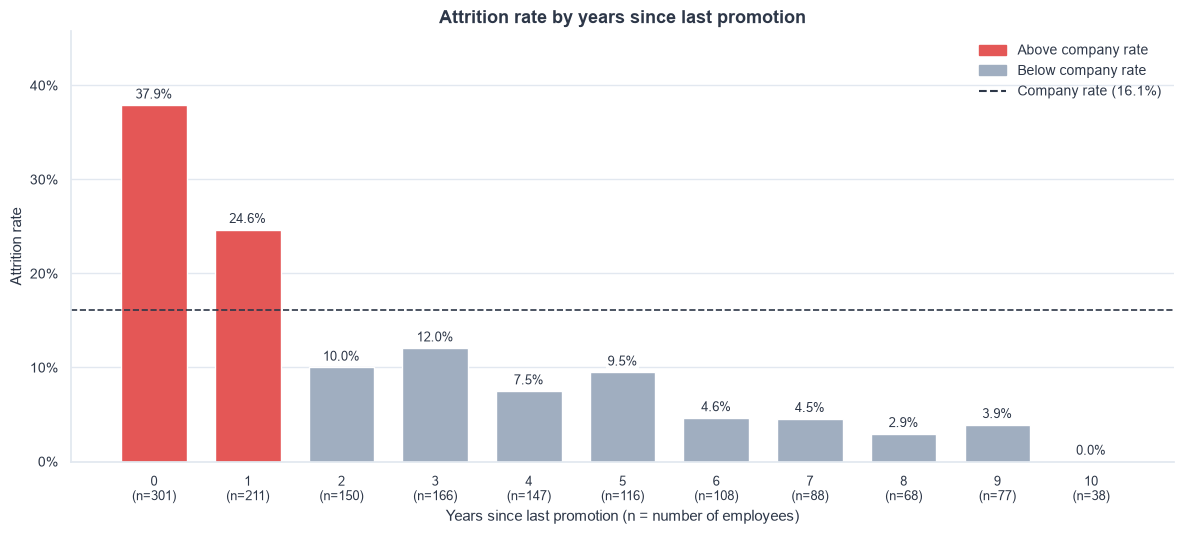

In [38]:
print("Correlation between YearsSinceLastPromotion and YearsAtCompany:",
      round(employee["YearsSinceLastPromotion"].corr(employee["YearsAtCompany"]), 2))

promo = employee.groupby("YearsSinceLastPromotion")["Left"].agg(employees="count", rate=lambda s: s.mean() * 100)
print(promo.round(1))

fig, ax = plt.subplots(figsize=(12, 5.5))
promo_colors = [COLORS["left"] if v > company_rate else COLORS["neutral"] for v in promo["rate"]]
bars = ax.bar(range(len(promo)), promo["rate"], color=promo_colors, width=0.7)
label_bars(ax, bars, labels=[f"{r:.1f}%" for r in promo["rate"]], padding=3, fontsize=9)
ax.axhline(company_rate, color=COLORS["text"], linestyle="--", linewidth=1.2)
ax.set_xticks(range(len(promo)))
ax.set_xticklabels([f"{y}\n(n={n})" for y, n in zip(promo.index, promo["employees"])], fontsize=9)
add_headroom(ax, "y", 0.15)
percent_axis(ax, "y")
ax.set_title("Attrition rate by years since last promotion")
ax.set_xlabel("Years since last promotion (n = number of employees)")
ax.set_ylabel("Attrition rate")
ax.legend(handles=[
    Patch(color=COLORS["left"], label="Above company rate"),
    Patch(color=COLORS["neutral"], label="Below company rate"),
    Line2D([0], [0], color=COLORS["text"], linestyle="--", label=f"Company rate ({company_rate:.1f}%)"),
], frameon=False, loc="upper right")
save_chart("06_attrition_by_years_since_promotion")

## 8. Self rating vs manager rating
`RatingGap = ManagerRating - SelfRating`. A negative number means the manager gave a lower rating than the employee gave to himself or herself.

RatingGap
Manager lower     51.1
Same              48.9
Manager higher     0.0
Name: count, dtype: float64

SelfRating       3.98
ManagerRating    3.47
dtype: float64


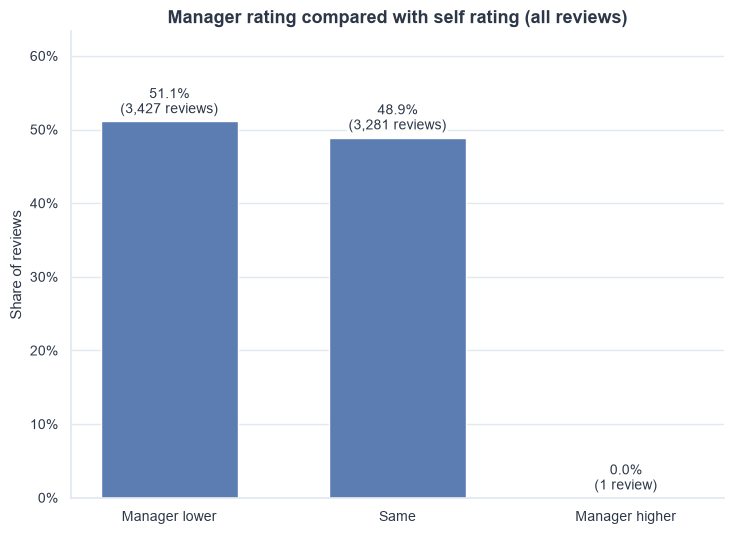

In [39]:
performance["RatingGap"] = performance["ManagerRating"] - performance["SelfRating"]

def gap_label(x):
    if x < 0:
        return "Manager lower"
    if x == 0:
        return "Same"
    return "Manager higher"

categories = ["Manager lower", "Same", "Manager higher"]
gap_counts = performance["RatingGap"].map(gap_label).value_counts().reindex(categories).fillna(0).astype(int)
gap_share = (gap_counts / gap_counts.sum() * 100).round(1)
print(gap_share)
print()
print(performance[["SelfRating", "ManagerRating"]].mean().round(2))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
bars = ax.bar(categories, gap_share.values, color=COLORS["primary"], width=0.6)
bar_text = [f"{p:.1f}%\n({n:,} {'review' if n == 1 else 'reviews'})" for p, n in zip(gap_share.values, gap_counts.values)]
label_bars(ax, bars, labels=bar_text, padding=3, fontsize=10)
add_headroom(ax, "y", 0.18)
percent_axis(ax, "y")
ax.set_title("Manager rating compared with self rating (all reviews)")
ax.set_xlabel("")
ax.set_ylabel("Share of reviews")
save_chart("07_self_vs_manager_rating")

## 9. Satisfaction and ratings: employees who left vs stayed
Each employee can have several reviews, so we first take the **average per employee**, then compare the two groups. Only employees with at least one review are included.

`TrainingOpportunitiesTaken` is a count and not a 1-5 score, so it is printed in the table but left out of the chart.

Employees included: 1280
                            Stayed  Left
EnvironmentSatisfaction       3.84  3.88
JobSatisfaction               3.41  3.45
RelationshipSatisfaction      3.40  3.44
WorkLifeBalance               3.41  3.42
TrainingOpportunitiesTaken    1.03  1.01
SelfRating                    3.97  3.99
ManagerRating                 3.47  3.46


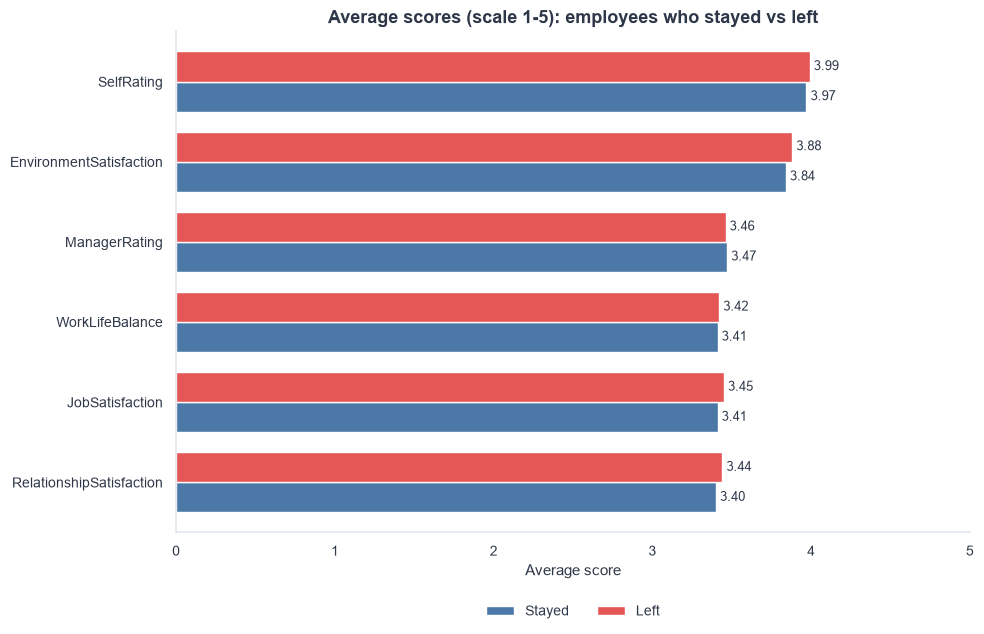

In [40]:
score_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction",
              "WorkLifeBalance", "TrainingOpportunitiesTaken", "SelfRating", "ManagerRating"]

per_employee = performance.groupby("EmployeeID")[score_cols].mean().reset_index()
merged = per_employee.merge(employee[["EmployeeID", "Left"]], on="EmployeeID", how="inner")
print("Employees included:", len(merged))

avg_scores = merged.groupby("Left")[score_cols].mean().T.round(2)
avg_scores.columns = ["Stayed", "Left"]
print(avg_scores)

chart_cols = [c for c in score_cols if c != "TrainingOpportunitiesTaken"]
plot_scores = avg_scores.loc[chart_cols].sort_values("Stayed")

ax = plot_scores.plot(kind="barh", figsize=(10, 6.5), color=[COLORS["stayed"], COLORS["left"]], width=0.75)
add_labels(ax, fmt="%.2f", fontsize=9)
ax.set_xlim(0, 5)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Average scores (scale 1-5): employees who stayed vs left")
ax.set_xlabel("Average score")
ax.set_ylabel("")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
save_chart("08_scores_left_vs_stayed")

## 10. More factors
Marital status, business travel, and stock option level.

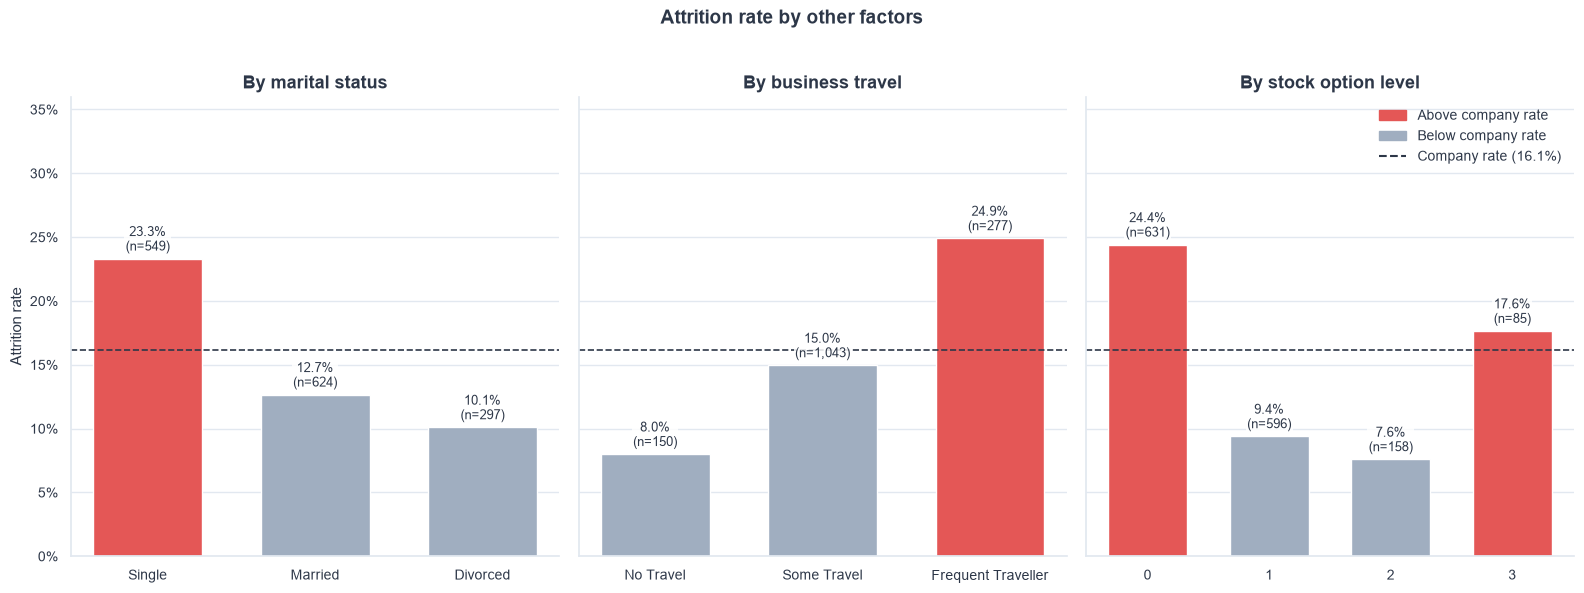

In [41]:
factors = {
    "MaritalStatus": ("marital status", ["Single", "Married", "Divorced"]),
    "BusinessTravel": ("business travel", ["No Travel", "Some Travel", "Frequent Traveller"]),
    "StockOptionLevel": ("stock option level", [0, 1, 2, 3]),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True)

for ax, (col, (name, order_)) in zip(axes, factors.items()):
    g = employee.groupby(col)["Left"].agg(["count", "mean"]).reindex(order_)
    rates = g["mean"] * 100
    colors = [COLORS["left"] if v > company_rate else COLORS["neutral"] for v in rates]
    bars = ax.bar([str(x) for x in order_], rates, color=colors, width=0.65)
    label_bars(ax, bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in zip(rates, g["count"])], padding=3, fontsize=9)
    ax.axhline(company_rate, color=COLORS["text"], linestyle="--", linewidth=1.2)
    ax.set_title(f"By {name}")
    ax.set_xlabel("")

axes[0].set_ylabel("Attrition rate")
axes[0].set_ylim(0, 36)
percent_axis(axes[0], "y")
axes[2].legend(handles=[
    Patch(color=COLORS["left"], label="Above company rate"),
    Patch(color=COLORS["neutral"], label="Below company rate"),
    Line2D([0], [0], color=COLORS["text"], linestyle="--", label=f"Company rate ({company_rate:.1f}%)"),
], frameon=False, loc="upper right")
fig.suptitle("Attrition rate by other factors", fontsize=14, fontweight="bold", y=1.02)
save_chart("09_more_factors")

## 11. Sales Representative deep dive
Sales Representative has the highest attrition rate. What does the data say about this group?

**Important limit:** this dataset has no commission or sales target columns, and we do not know if `Salary` includes commission. So we can look at salary, overtime, time at the company, and review scores, but we cannot check target achievement.

In [42]:
rep = employee[employee["JobRole"] == "Sales Representative"]
print(f"Sales Representatives: {len(rep)} | left: {rep['Left'].sum()} | attrition rate: {rep['Left'].mean() * 100:.1f}%")

salary_compare = pd.Series({
    "Sales Rep - stayed": rep.loc[rep["Left"] == 0, "Salary"].median(),
    "Sales Rep - left": rep.loc[rep["Left"] == 1, "Salary"].median(),
    "Sales Executive (all)": employee.loc[employee["JobRole"] == "Sales Executive", "Salary"].median(),
    "Company (all)": employee["Salary"].median(),
})
print()
print("Median salary:")
print(salary_compare.round(0))

print()
print("Median years at company (Sales Representatives):")
print(rep.groupby("Status")["YearsAtCompany"].median())

rep_ot = rep.groupby("OverTime")["Left"].agg(employees="count", left="sum", rate=lambda s: s.mean() * 100)
print()
print(rep_ot.round(1))

Sales Representatives: 83 | left: 33 | attrition rate: 39.8%

Median salary:
Sales Rep - stayed        42910.0
Sales Rep - left          32894.0
Sales Executive (all)    100314.0
Company (all)             71200.0
dtype: float64

Median years at company (Sales Representatives):
Status
Left      2.0
Stayed    4.0
Name: YearsAtCompany, dtype: float64

          employees  left  rate
OverTime                       
No               59    17  28.8
Yes              24    16  66.7


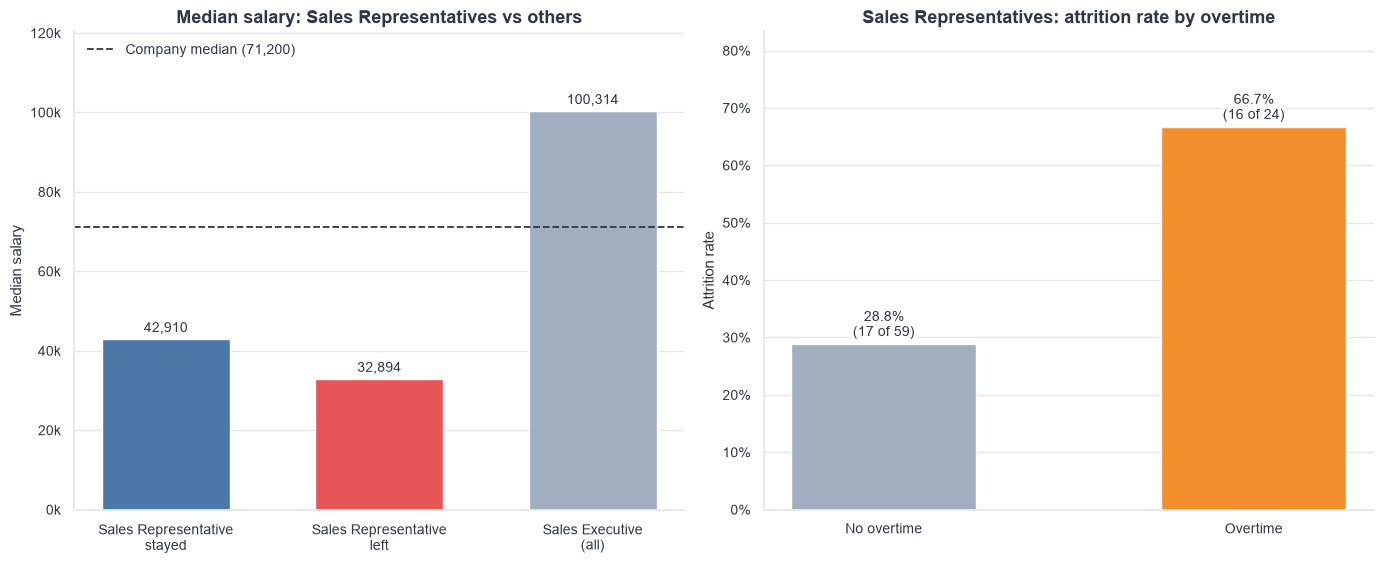

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

names = ["Sales Representative\nstayed", "Sales Representative\nleft", "Sales Executive\n(all)"]
values = [salary_compare["Sales Rep - stayed"], salary_compare["Sales Rep - left"], salary_compare["Sales Executive (all)"]]
company_median = salary_compare["Company (all)"]

bars = axes[0].bar(names, values, color=[COLORS["stayed"], COLORS["left"], COLORS["neutral"]], width=0.6)
label_bars(axes[0], bars, labels=[f"{v:,.0f}" for v in values], padding=3, fontsize=10)
axes[0].axhline(company_median, color=COLORS["text"], linestyle="--", linewidth=1.3,
                label=f"Company median ({company_median:,.0f})")
axes[0].set_ylim(0, max(values) * 1.2)
k_axis(axes[0], "y")
axes[0].set_title("Median salary: Sales Representatives vs others")
axes[0].set_ylabel("Median salary")
axes[0].legend(frameon=False, loc="upper left")

bars = axes[1].bar(["No overtime", "Overtime"], rep_ot["rate"], color=[COLORS["neutral"], COLORS["accent"]], width=0.5)
label_bars(axes[1], bars, labels=[f"{r:.1f}%\n({l} of {n})" for r, l, n in zip(rep_ot["rate"], rep_ot["left"], rep_ot["employees"])],
                  padding=3, fontsize=10)
axes[1].set_ylim(0, rep_ot["rate"].max() * 1.25)
percent_axis(axes[1], "y")
axes[1].set_title("Sales Representatives: attrition rate by overtime")
axes[1].set_xlabel("")
axes[1].set_ylabel("Attrition rate")

save_chart("11_sales_representative_deep_dive")

Review scores of Sales Representatives (average per employee, only employees with reviews):

In [44]:
rep_scores = per_employee.merge(rep[["EmployeeID", "Status"]], on="EmployeeID")
print("Sales Representatives with reviews:", len(rep_scores), "of", len(rep))
rep_scores.groupby("Status")[["SelfRating", "ManagerRating", "JobSatisfaction", "WorkLifeBalance", "TrainingOpportunitiesTaken"]].mean().round(2)

Sales Representatives with reviews: 72 of 83


,SelfRating,ManagerRating,JobSatisfaction,WorkLifeBalance,TrainingOpportunitiesTaken
Status,,,,,
Left,3.92,3.37,3.44,3.39,0.96
Stayed,3.97,3.46,3.23,3.66,1.03


## 12. High-risk segment and KPIs
A good KPI is a number that points to an action. Two things stood out: overtime and the first two years at the company. What happens when we combine them?

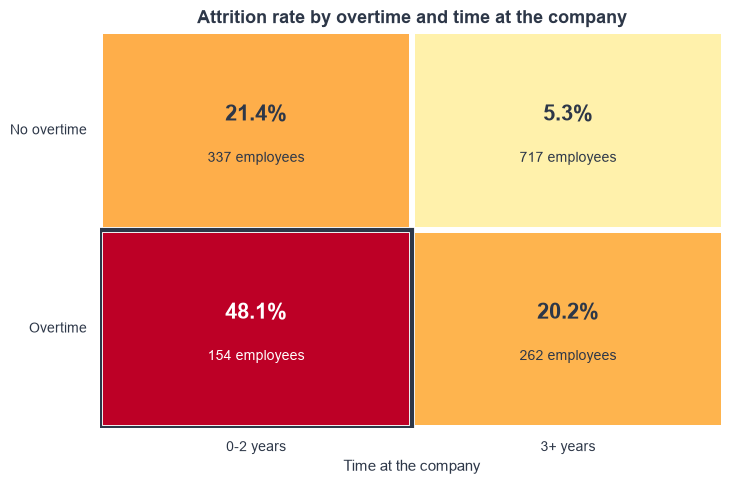

In [45]:
employee["TenureBand"] = employee["YearsAtCompany"].apply(lambda y: "0-2 years" if y <= 2 else "3+ years")

heat = employee.pivot_table(index="OverTime", columns="TenureBand", values="Left", aggfunc="mean") * 100
counts = employee.pivot_table(index="OverTime", columns="TenureBand", values="Left", aggfunc="count")

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(heat, annot=False, cmap="YlOrRd", vmin=0, vmax=55, linewidths=4, linecolor="white", cbar=False, ax=ax)

for r, row_name in enumerate(heat.index):
    for c, col_name in enumerate(heat.columns):
        value = heat.loc[row_name, col_name]
        n = int(counts.loc[row_name, col_name])
        color = "white" if value >= 35 else COLORS["text"]
        ax.text(c + 0.5, r + 0.42, f"{value:.1f}%", ha="center", va="center", fontsize=16, fontweight="bold", color=color)
        ax.text(c + 0.5, r + 0.64, f"{n:,} employees", ha="center", va="center", fontsize=10, color=color)

# frame the high-risk cell (overtime, 0-2 years)
ax.add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor=COLORS["text"], linewidth=3))

ax.set_xticklabels(heat.columns, rotation=0)
ax.set_yticklabels(["No overtime", "Overtime"], rotation=0)
ax.set_title("Attrition rate by overtime and time at the company")
ax.set_xlabel("Time at the company")
ax.set_ylabel("")
save_chart("12_high_risk_segment")

In [46]:
high_risk = employee[(employee["OverTime"] == "Yes") & (employee["YearsAtCompany"] <= 2)]
low_risk = employee[(employee["OverTime"] == "No") & (employee["YearsAtCompany"] > 2)]

kpis = pd.DataFrame({
    "KPI": [
        "Company attrition rate (%)",
        "Attrition rate in the first 2 years (%)",
        "Overtime attrition gap (percentage points)",
        "High-risk segment: employees (overtime and 0-2 years)",
        "High-risk segment: attrition rate (%)",
        "High-risk segment: share of all employees who left (%)",
        "Lowest-risk segment attrition rate (no overtime, 3+ years) (%)",
        "Sales Representative attrition rate (%)",
    ],
    "Value": [
        employee["Left"].mean() * 100,
        employee.loc[employee["YearsAtCompany"] <= 2, "Left"].mean() * 100,
        (employee.loc[employee["OverTime"] == "Yes", "Left"].mean() - employee.loc[employee["OverTime"] == "No", "Left"].mean()) * 100,
        len(high_risk),
        high_risk["Left"].mean() * 100,
        high_risk["Left"].sum() / employee["Left"].sum() * 100,
        low_risk["Left"].mean() * 100,
        rep["Left"].mean() * 100,
    ],
}).round(1)

kpis.to_csv("../data/clean/kpi_summary.csv", index=False)
kpis

,KPI,Value
0,Company attrition rate (%),16.1
1,Attrition rate in the first 2 years (%),29.7
2,Overtime attrition gap (percentage points),20.1
3,High-risk segment: employees (overtime and 0-2...,154.0
4,High-risk segment: attrition rate (%),48.1
5,High-risk segment: share of all employees who ...,31.2
6,Lowest-risk segment attrition rate (no overtim...,5.3
7,Sales Representative attrition rate (%),39.8


## My notes

**What I found**
- Salaries are skewed: the median is 71,199 and the mean is 112,956. I use the median when I compare salaries.
- Comparing with all employees, 124 salaries look like outliers, but most belong to managers, where high pay is normal. Inside each job role, only 41 are outliers.
- A few salaries look unusual for their role, for example a Data Scientist at 455,643 and a Software Engineer at 439,641, while the median of these roles is about 43,000-44,000. I kept them because I cannot confirm that they are errors.
- Overtime: attrition is higher with overtime in 8 of 9 job roles with 30+ employees (Sales Representative 28.8% to 66.7%, Data Scientist 15.7% to 49.2%, Software Engineer 7.1% to 33.7%). Senior Software Engineer is the exception.
- Attrition is highest in the first two years at the company (31.6% and 34.5%) and falls to 0.8% at 10 years. Employees aged 18-35 left about 18-20% of the time, compared with 5.6-7.5% for ages 36-55.
- Attrition falls as years since the last promotion increase. This is strongly linked to years at the company (correlation 0.87), so it mostly reflects tenure and not the promotion itself.
- Managers rated lower than the self rating in 51.1% of reviews, the same in 48.9%, and higher in only 1 of 6,709 reviews (average 3.47 vs 3.98).
- Satisfaction scores are almost the same for employees who left and who stayed (job satisfaction 3.41 vs 3.45, work-life balance 3.41 vs 3.42).
- Single employees (23.3%), frequent travellers (24.9%), and employees with no stock options (24.4%) have higher attrition rates.
- Sales Representatives: 39.8% left (33 of 83). Their median salary is 36,101, compared with 100,314 for Sales Executives and 71,199 for the company. Representatives who left had a lower median salary than those who stayed (32,894 vs 42,910) and a shorter time at the company (median 2 vs 4 years). Among representatives who work overtime, 66.7% left (16 of 24), compared with 28.8% (17 of 59) without overtime.
- High-risk segment: employees who work overtime and have 0-2 years at the company. They are 154 employees (10.5% of the company), their attrition rate is 48.1%, and they account for 74 of the 237 employees who left (31%). The lowest-risk group (no overtime, 3+ years) has an attrition rate of 5.3%.

**What I need to be careful about**
- These are relationships, not causes. I cannot say that overtime, travel, or marital status makes employees leave.
- The factors overlap (age, tenure, job role, overtime). One chart cannot separate their effects.
- Some groups are small (for example Analytics Manager with 52 employees), so their rates are less reliable.
- Satisfaction scores exist only for employees with reviews (1,280 of 1,470).
- The review dates before hire dates limit any analysis over time.
- There are no commission or sales target columns, and I do not know if Salary includes commission. So I cannot test if low target achievement explains why Sales Representatives leave. This is the most important missing data for this question.

**What I want to do next**
- Summarize the main results with Excel PivotTables.
- Build a Power BI dashboard with an overview page and an attrition page.
- Write the final insights and recommendations, including a request for commission and target data for Sales Representatives.